# **TALLER METODO AHP PARA PROBLEMAS MULTIOBJETIVO  DISCRETOS**

#**ELECCION CARRO ELECTRICO**

Curso: Introducción al Análisis de Decisiones

Universidad Nacional de Colombia, Sede Medellín

Realizado por Profesora Patricia Jaramillo y estudiante Luis José Mejía

Fecha actualización: 13 de Julio de 2026


```

```



### NOTA, buscar etiqueta: %RELLENAR% para encontrar rapidamente las matrices que debe llenar.



:### Recordatorio teórico

**Problemas multiobjetivo discretos.** El número de alternativas es finito y se listan explícitamente (p. ej. *¿cuál proveedor elegir?*). Se resumen en una **matriz de consecuencias** (criterios en filas, alternativas en columnas), a diferencia de los problemas continuos, que se modelan con ecuaciones.

**Método AHP (Saaty, 1980).** Jerarquiza el problema en niveles (objetivo >> criterios >> subcriterios >> alternativas) para que el decisor estructure y clarifique el problema. Los criterios de un mismo nivel deben ser **independientes**. Sus pasos son:

1. Diseñar el árbol jerárquico de criterios.
2. Definir las alternativas en el último nivel del árbol.
3. Asignar pesos a los vínculos del árbol (pesos locales y globales).
4. Valorar las alternativas respecto a cada criterio.
5. Normalizar la matriz de consecuencias.
6. Valorar las alternativas por una regla de decisión (AHP por defecto es con suma ponderada).
7. Análisis de sensibilidad.
8. Decisión.

**Escala de comparación pareada de Saaty.** Al comparar dos elementos $i$ y $j$ respecto al nivel superior que comparten, se asigna un valor de la siguiente escala (y su recíproco en la celda simétrica):

| Si $i$ es ... que $j$        | Valor |
|------------------------------|:-----:|
| Igualmente importante        | 1 |
| Apenas más importante        | 3 |
| Bastante más importante      | 5 |
| Mucho más importante         | 7 |
| Absolutamente más importante | 9 |

Los números pares (2, 4, 6, 8) representan situaciones intermedias. Si $a_{ij}$ es el juicio de la fila $i$ frente a la columna $j$, entonces $a_{ji} = 1/a_{ij}$ y la diagonal es 1.


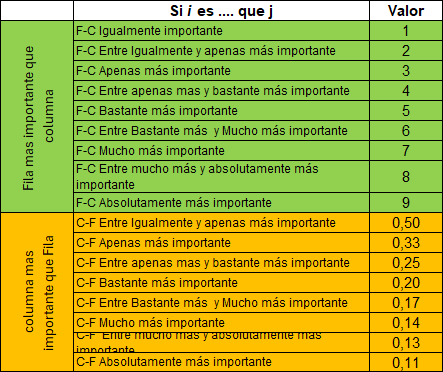

## **Aplicación del Método AHP: Caso de Selección de un carro eléctrico**


%RELLENAR%Esta plantilla está muy completa. Usted solo debe:

1.	Construya las matrices de comparación pareada del caso del automóvil (matriz principal Costo/Seguridad/Capacidad, y los macrocriterios Costo y Capacidad) con sus propias preferencias y verifique con analizar_consistencia que cada una cumple CR≤0.10. Si alguna no cumple, ajuste sus juicios y explique qué cambió.

2.	Cambie el modelo y datos de la primera columna de las alternativas: Apóyese en internet. Si no encuentra un dato asúmalo de forma realista

3.	Analice la jerarquía y elija su carro.


4.	Haga análisis de sensibilidad cambiando los pesos ligeramente por encima y por debajo. Sigue ganando la misma alternativa? (Es decir, es robusta al cambio de pesos?)

5.	Haga análisis de sensibilidad, mediante simulación de Montecarlo. ¿Cuál es la alternativa más robusta al cambio de pesos? _________________________ ¿Por qué?




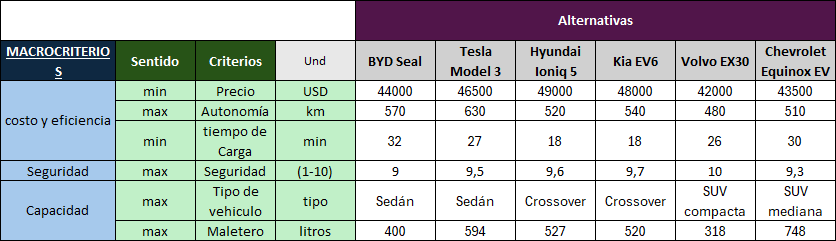

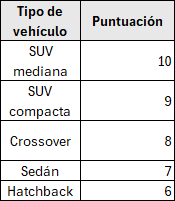

## **Paso 1: Dibujar el árbol del problema**

In [2]:
# Importar librerías para dibujar el árbol del problema
from graphviz import Digraph
from IPython.display import Image

In [3]:
# En la variable dot se almacena el diagrama
dot = Digraph()

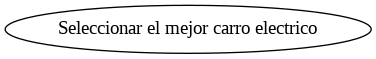

In [4]:
# A continuación se define la capa superior (Nivel 1) donde se indica el OBJETIVO del árbol

# Nivel 1: Objetivo principal
dot.node('A', 'Seleccionar el mejor carro electrico')

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

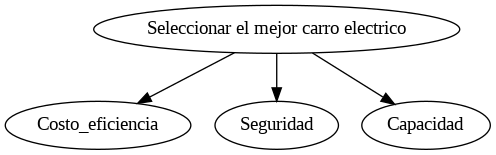

In [5]:
# A continuación se define la siguiente capa (Nivel 2) donde se indican los CRITERIOS del árbol

# Nivel 2: Criterios
dot.node('B', 'Costo_eficiencia')
dot.node('C', 'Seguridad')
dot.node('D', 'Capacidad')

# Enlaces (Del nodo A del Nivel 1 se definen enlaces para cada uno de los nodos del Nivel 2)
dot.edges(['AB', 'AC', 'AD'])

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

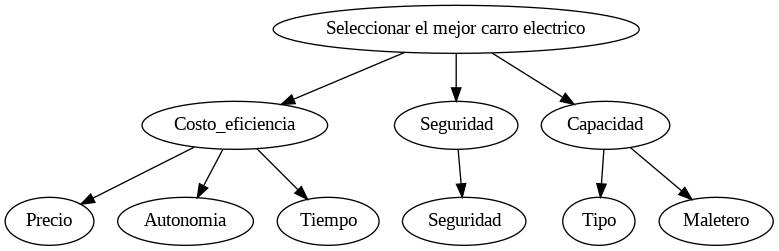

In [6]:
# A continuación se define la siguiente capa (Nivel 3) donde se indican los SUBCRITERIOS del árbol

# Nivel 3: Subcriterios
dot.node('E', 'Precio')
dot.node('F', 'Autonomia')
dot.node('G', 'Tiempo')
dot.node('H', 'Seguridad')
dot.node('I', 'Tipo')
dot.node('J', 'Maletero')

# Enlaces (De los nodos del Nivel 2 se definen enlaces para cada uno de los nodos del Nivel 3)
dot.edges(['BE', 'BF', 'BG', 'CH', 'DI', 'DJ'])

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

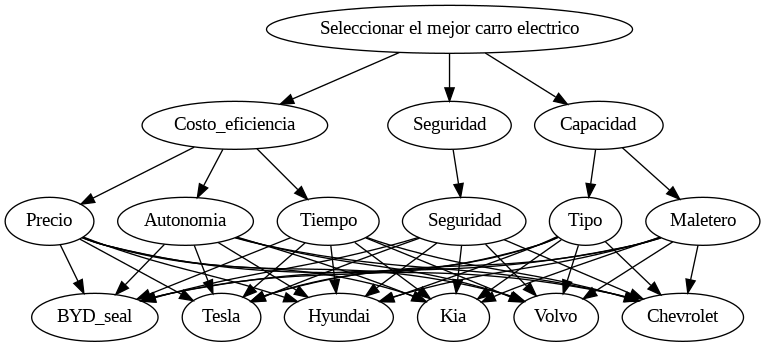

In [7]:
# Ahora se define la siguiente capa (Nivel 4) donde se indican las ALTERNATIVAS del árbol

# Nivel 4: Alternativas
dot.node('K', 'BYD_seal')
dot.node('L', 'Tesla')
dot.node('M', 'Hyundai')
dot.node('N', 'Kia')
dot.node('O', 'Volvo')
dot.node('P', 'Chevrolet')

# Enlaces (De los nodos del Nivel 3 se definen enlaces para cada uno de los nodos del Nivel 4)
dot.edges(['EK', 'EL', 'EM','EN', 'EO', 'EP',
           'FK', 'FL', 'FM', 'FN', 'FO', 'FP',
           'GK', 'GL', 'GM', 'GN', 'GO', 'GP',
           'HK', 'HL', 'HM', 'HN', 'HO', 'HP',
           'IK', 'IL', 'IM', 'IN', 'IO', 'IP',
           'JK', 'JL', 'JM', 'JN', 'JO', 'JP'])

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

## **Paso 2: Calcular los pesos de los criterios locales**

In [8]:
# Se importa la librería numpy para realizar cálculos matemáticos
import numpy as np
# Se importa la librería pandas para manipular tablas
import pandas as pd

**Comparaciones pareadas nivel 1 (Costo y eficiencia, Seguridad, Capacidad)

Por ejemplo, suponga que el decisor asignó las comparaciones (fila respecto a columna) que se presenta a continuación:

In [9]:
# El vector propio (pesos de los criterios) se encuentra el siguiente procedimiento
# Este procedimiento recibe como entrada la matriz de comparaciones
# Este procedimiento entrega como resultado los pesos y el máximo valor propio

def calcular_pesos(matriz):
    eigenvalues, eigenvectors = np.linalg.eig(matriz)
    max_eigenvalue = np.max(eigenvalues).real
    index = np.argmax(eigenvalues).real
    pesos = eigenvectors[:, index].real
    pesos = pesos / pesos.sum()
    return pesos, max_eigenvalue

### %RELLENAR% En matriz_Criterios ponga sus pesos

1.   Elemento de la lista
2.   Elemento de la lista



In [10]:
matriz_Criterios = np.array([ [1  , 1,   1],
                              [1/1, 1,   1],
                              [1/1, 1/1, 1]])

### Representación gráfica de la matriz de comparaciones de los criterios

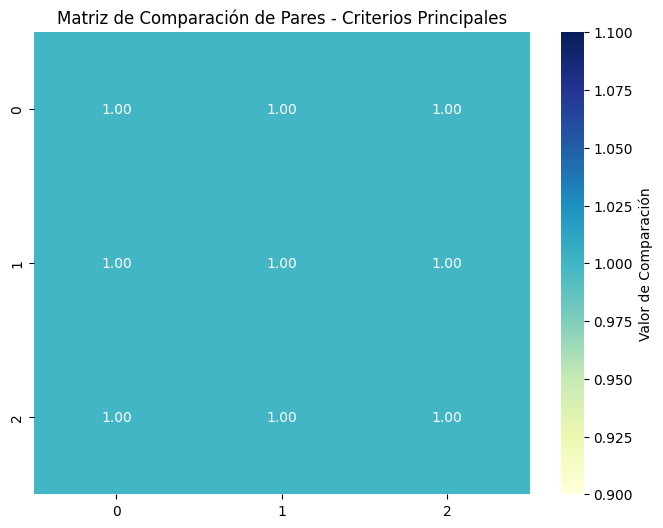

In [11]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_Criterios, annot=True, cmap='YlGnBu', fmt='.2f', cbar_kws={'label': 'Valor de Comparación'})
plt.title('Matriz de Comparación de Pares - Criterios Principales')
plt.show()

Cálculo de los pesos y del máximo de los valores propios

In [12]:
pesos_criterios, max_eigenvalueCriterios = calcular_pesos(matriz_Criterios)
print("Pesos de los criterios principales:", pesos_criterios)
print("Máximo valor propio de criterios:", max_eigenvalueCriterios)

Pesos de los criterios principales: [0.33333333 0.33333333 0.33333333]
Máximo valor propio de criterios: 3.0


#### Cálculo alternativo aproximado y simple: cálculo de pesos por normalización de columnas

El procedimiento `calcular_pesos` usa el **vector propio** de la matriz de comparaciones (método exacto de Saaty). En clase se presenta un método aproximado y muy intuitivo: **normalizar cada columna** (dividir por su suma) y luego **promediar por filas**. Ambos métodos deben dar pesos muy parecidos cuando la matriz es consistente. A continuación se implementa el método de la clase y se compara con el del vector propio, sin modificar nada de lo anterior.


In [13]:
# Metodo de la clase: normalizar por columnas y promediar por filas
# (Se agrega como complemento; no reemplaza a calcular_pesos)
def pesos_normalizacion_columnas(matriz):
    matriz = np.array(matriz, dtype=float)
    # Se normaliza cada columna dividiendola por la suma de la columna
    columnas_normalizadas = matriz / matriz.sum(axis=0)
    # El peso de cada criterio es el promedio de su fila normalizada
    pesos = columnas_normalizadas.mean(axis=1)
    return pesos

pesos_criterios_colnorm = pesos_normalizacion_columnas(matriz_Criterios)

print("Pesos por vector propio (calcular_pesos):", np.round(pesos_criterios, 4))
print("Pesos por normalizacion de columnas    :", np.round(pesos_criterios_colnorm, 4))
print("Diferencia maxima entre ambos metodos  :",
      np.round(np.abs(pesos_criterios - pesos_criterios_colnorm).max(), 5))


Pesos por vector propio (calcular_pesos): [0.3333 0.3333 0.3333]
Pesos por normalizacion de columnas    : [0.3333 0.3333 0.3333]
Diferencia maxima entre ambos metodos  : 0.0


## **Paso 3: Cálculo del índice de consistencia**

El Índice de Consistencia (CI) se calcula con la fórmula:

$$\text{CI} = \frac{\lambda_{\text{max}} - n}{n - 1}$$

donde $n$ es el tamaño de la matriz.

La Razón de Consistencia (CR) se calcula como:

$$\text{CR} = \frac{\text{CI}}{\text{RI}}$$

donde $\text{RI}$ es el Índice Aleatorio correspondiente al tamaño de la matriz. Los valores de RI para diferentes tamaños de matrices son:

$$
\text{RI}_{n} = \begin{cases}
0.00 & \text{si } n = 1 \text{ o } 2 \\
0.58 & \text{si } n = 3 \\
0.90 & \text{si } n = 4 \\
1.12 & \text{si } n = 5 \\
1.24 & \text{si } n = 6 \\
\vdots
\end{cases}
$$

La razón de consistencia debe ser menor a 0,1 para que los resultados sean coherentes. En una matriz de orden 2 no es necesario calcular la razón de consistencia.

**Nota adicional:**
Saaty obtuvo los valores del Índice Aleatorio (RI) mediante un experimento de simulación matemática por computadora, simulando (con muchísimas iteraciones) qué pasaría si alguien respondiera a la matriz de comparaciones de forma completamente al azar. Esto lo hizo para diferentes tamaños de matrices.

El índice aleatorio es el promedio de los Índices de Consistencia (CI) de cada una de esas miles de matrices aleatorias.

CR= CI /RI, significa que tan cerca esta la matriz dada, de una al azar

Si  CR= 1.0, las respuestas dadas  son indistinguibles de respuestas generadas al azar.

Saaty estableció un límite empírico razonable de 0.10 para aceptar las respuestas como válidas.


In [14]:
# El índice de consistencia se calcula con el siguiente procedimiento

# Este procedimiento recibe como entrada la matriz de comparaciones y el máximo valor propio
# Este procedimiento entrega como resultado el índice de consistencia

def indice_inconsistencia(matriz, max_eigenvalue):
    n = matriz.shape[0]
    CI = (max_eigenvalue - n) / (n - 1)
    return CI

# Este procedimiento recibe como entrada el índice de consistencia (CI) y el índice aleatorio (RI)
# Este procedimiento entrega como resultado la razón de consistencia (CR)



# Siguiendo los de excel (valores de Alonso-Lamata)
def razon_consistencia(CI, RI):
    CR = CI / RI
    RI_values = {
    1: 0.00, 2: 0.00, 3: 0.525, 4: 0.882, 5: 1.115,
    6: 1.252 ,7: 1.341, 8: 1.404, 9: 1.452, 10: 1.484
    }
    return CR

In [15]:
IndiceConsistencia_Criterios = indice_inconsistencia(matriz_Criterios, max_eigenvalueCriterios)
print("Índice de Consistencia de Criterios:", IndiceConsistencia_Criterios)

# Recuerde actualizar el valor de RI (índice aleatorio, random index)
RazonCosistencia_Criterios = razon_consistencia(IndiceConsistencia_Criterios, 0.58)    #0.58 por ser matriz de tamaño 3
print("Razón de Consistencia de Criterios:", RazonCosistencia_Criterios)

Índice de Consistencia de Criterios: 0.0
Razón de Consistencia de Criterios: 0.0


## **Paso 4: Calcular los pesos locales de los subcriterios**

Por ejemplo, suponga que el decisor dio las siguientes respuestas de comparaciones pareadas

### %RELLENAR% en matriz_Costo y matriz_Capacidad, ponga sus pesos.

In [16]:
matriz_Costo    = np.array([[1  , 1, 1],
                            [1, 1, 1],
                            [1 , 1, 1]])

pesos_Costo, max_eigenvalueCosto = calcular_pesos(matriz_Costo)
print("Pesos de los subcriterios de costo:", pesos_Costo)

print("Pesos de los subcriterios de seguridad:", pesos_criterios[1] )  #no tiene sino un hijo, no necesita matriz de comparacion

matriz_Capacidad  = np.array([[1  , 1],
                            [1, 1]])

pesos_Capacidad, max_eigenvalueCapacidad = calcular_pesos(matriz_Capacidad)
print("Pesos de los subcriterios de capacidad:", pesos_Capacidad)



Pesos de los subcriterios de costo: [0.33333333 0.33333333 0.33333333]
Pesos de los subcriterios de seguridad: 0.33333333333333326
Pesos de los subcriterios de capacidad: [0.5 0.5]


## **Paso 5: Calcular los pesos globales de los subcriterios**

Los pesos globales de un nodo del árbol se calculan mediante la multiplicacion de todos los pesos que están en niveles superiores a ese nodo

In [17]:
Peso_Precio      = pesos_criterios[0] * pesos_Costo[0]
Peso_Autonomia   = pesos_criterios[0] * pesos_Costo[1]
Peso_Tiempo      = pesos_criterios[0] * pesos_Costo[2]
Peso_Seguridad   = pesos_criterios[1]
Peso_Tipo     =    pesos_criterios[2] * pesos_Capacidad[0]
Peso_Maletero     = pesos_criterios[2] * pesos_Capacidad[1]

vector_pesos_globales = np.array([Peso_Precio,
                                  Peso_Autonomia,
                                  Peso_Tiempo,
                                  Peso_Seguridad,
                                  Peso_Tipo,
                                  Peso_Maletero
                                  ])

print("Peso global del subcriterio Precio:", Peso_Precio)
print("Peso global del subcriterio Autonomia:", Peso_Autonomia)
print("Peso global del subcriterio Tiempo de carga:", Peso_Tiempo)
print("Peso global del subcriterio Seguridad:", Peso_Seguridad)
print("Peso global del subcriterio Tipo de carro:", Peso_Tipo)
print("Peso global del subcriterio Maletero:", Peso_Maletero)

print("Vector de pesos globales:", vector_pesos_globales)

Peso global del subcriterio Precio: 0.11111111111111113
Peso global del subcriterio Autonomia: 0.1111111111111111
Peso global del subcriterio Tiempo de carga: 0.11111111111111113
Peso global del subcriterio Seguridad: 0.33333333333333326
Peso global del subcriterio Tipo de carro: 0.16666666666666669
Peso global del subcriterio Maletero: 0.16666666666666669
Vector de pesos globales: [0.11111111 0.11111111 0.11111111 0.33333333 0.16666667 0.16666667]


## **Paso 6: Primera normalización de la matriz de consecuencias**

Se multiplica por -1 los criterios a minimizar y, los valores se llevan a una escala 0-1 para cada criterio (0 para el peor valor, 1 para el mejor valor de cada criterio)

In [18]:
# Crear el DataFrame con los datos de la matriz de consecuencias

# Nombres de las alternativas

# Matriz de consecuencias
data = [
    [-44000, -46500, -49000, -48000, -42000, -43500],      # C1=Precio
    [570, 630, 520, 540, 480, 510],                        # C2=autonomia
    [-32, -27, -18, -18, -26, -30],                        # C3=tiempo de carga
    [9, 9.5, 9.6, 9.7, 10, 9.3],                           # C4=seguridad
    [7, 7, 8, 8, 9, 10],                                   # C5=tipo de vehiculo
    [400, 594, 527, 520, 318, 748],                        # C6=maletero

]

criterios = ['Precio', 'Autonomia', 'Tiempo de carga', 'Seguridad', 'Tipo de vehiculo', 'Maletero']
#
# Nombres de las alternativas
alternativas = ['BYD_seal', 'Tesla', 'Hyundai', 'Kia', 'Volvo',
           'Chevrolet']

# Crear el DataFrame
matriz_consecuencias = pd.DataFrame(data, index=criterios, columns=alternativas)

# Mostrar el DataFrame
print(matriz_consecuencias)



                  BYD_seal    Tesla  Hyundai      Kia  Volvo  Chevrolet
Precio              -44000 -46500.0 -49000.0 -48000.0 -42000   -43500.0
Autonomia              570    630.0    520.0    540.0    480      510.0
Tiempo de carga        -32    -27.0    -18.0    -18.0    -26      -30.0
Seguridad                9      9.5      9.6      9.7     10        9.3
Tipo de vehiculo         7      7.0      8.0      8.0      9       10.0
Maletero               400    594.0    527.0    520.0    318      748.0


Se realiza la normalización de cada valor $Z_{ij}$ que corresponde al criterio $i$ en la alternativa $j$ mediante la siguiente expresión:


$$
Z_{ij}^{\text{norm}} = \frac{Z_{ij} - \min(Z_i)}{\max(Z_i) - \min(Z_i)}
$$

## **Paso 7: Segunda normalización de la matriz de consecuencias**

Para seguir la formalización del método AHP,  cada nodo padre debe repartir una unidad entre los nodos hijos: cada nodo criterio de ultimo nivel, debe repartir una unidad entre las alternativas.

In [19]:
# Normalización por filas usando min-max
matriz_normalizada = matriz_consecuencias.apply(lambda fila: (fila - fila.min()) / (fila.max() - fila.min()), axis=1)

print("Matriz normalizada por filas (min-max):")
print(matriz_normalizada.round(3))


Matriz normalizada por filas (min-max):
                  BYD_seal  Tesla  Hyundai    Kia  Volvo  Chevrolet
Precio               0.714  0.357    0.000  0.143  1.000      0.786
Autonomia            0.600  1.000    0.267  0.400  0.000      0.200
Tiempo de carga      0.000  0.357    1.000  1.000  0.429      0.143
Seguridad            0.000  0.500    0.600  0.700  1.000      0.300
Tipo de vehiculo     0.000  0.000    0.333  0.333  0.667      1.000
Maletero             0.191  0.642    0.486  0.470  0.000      1.000


In [20]:
# Normalización por filas (cada fila se divide por la suma de esa fila)
matriz_2normalizada = matriz_normalizada.div(matriz_normalizada.sum(axis=1), axis=0)

print("Matriz normalizada por filas:")
print(matriz_2normalizada.round(3))


Matriz normalizada por filas:
                  BYD_seal  Tesla  Hyundai    Kia  Volvo  Chevrolet
Precio               0.238  0.119    0.000  0.048  0.333      0.262
Autonomia            0.243  0.405    0.108  0.162  0.000      0.081
Tiempo de carga      0.000  0.122    0.341  0.341  0.146      0.049
Seguridad            0.000  0.161    0.194  0.226  0.323      0.097
Tipo de vehiculo     0.000  0.000    0.143  0.143  0.286      0.429
Maletero             0.068  0.230    0.174  0.168  0.000      0.359


In [21]:
# verificamos estar normalizando correctamente
for index, row in matriz_2normalizada.iterrows():
    row_sum = row.sum()
    print(f"La fila '{index}' suma: {row_sum:.6f}")

La fila 'Precio' suma: 1.000000
La fila 'Autonomia' suma: 1.000000
La fila 'Tiempo de carga' suma: 1.000000
La fila 'Seguridad' suma: 1.000000
La fila 'Tipo de vehiculo' suma: 1.000000
La fila 'Maletero' suma: 1.000000


## **Paso 8: Ponderar los pesos globales (de criterios de último nivel) con los valores de la matriz de consecuencias doblemente normalizada**

In [22]:
matriz_ponderada = matriz_2normalizada.mul(vector_pesos_globales, axis=0)

print("Matriz ponderada:")
print(matriz_ponderada.round(4))

Matriz ponderada:
                  BYD_seal   Tesla  Hyundai     Kia   Volvo  Chevrolet
Precio              0.0265  0.0132   0.0000  0.0053  0.0370     0.0291
Autonomia           0.0270  0.0450   0.0120  0.0180  0.0000     0.0090
Tiempo de carga     0.0000  0.0136   0.0379  0.0379  0.0163     0.0054
Seguridad           0.0000  0.0538   0.0645  0.0753  0.1075     0.0323
Tipo de vehiculo    0.0000  0.0000   0.0238  0.0238  0.0476     0.0714
Maletero            0.0114  0.0384   0.0291  0.0281  0.0000     0.0598


In [23]:
puntajes_totales = matriz_ponderada.sum(axis=0)

print("Puntaje total por proveedor:")
print(puntajes_totales.round(4))

Puntaje total por proveedor:
BYD_seal     0.0649
Tesla        0.1640
Hyundai      0.1673
Kia          0.1884
Volvo        0.2084
Chevrolet    0.2070
dtype: float64


In [24]:
mejor_carro = puntajes_totales.idxmax()
mejor_valor = puntajes_totales.max()

print(f"El mejor carro es {mejor_carro} con un puntaje de {mejor_valor:.4f}")

El mejor carro es Volvo con un puntaje de 0.2084


### Resumen de resultados del Taller 1

Se consolidan los puntajes AHP y la jerarquía final en una sola tabla para facilitar la lectura de la decisión.


In [25]:
# Tabla resumen: puntaje AHP y jerarquia por proveedor
resumen_AHP = pd.DataFrame({"Puntaje AHP": puntajes_totales.round(4)})
resumen_AHP["Jerarquia"] = resumen_AHP["Puntaje AHP"].rank(ascending=False).astype(int)
resumen_AHP = resumen_AHP.sort_values("Jerarquia")

print("Resumen final del Taller 1 (1 = mejor):")
print(resumen_AHP)
print(f"\nDecision: el mejor carro es {mejor_carro} con puntaje {mejor_valor:.4f}.")


Resumen final del Taller 1 (1 = mejor):
           Puntaje AHP  Jerarquia
Volvo           0.2084          1
Chevrolet       0.2070          2
Kia             0.1884          3
Hyundai         0.1673          4
Tesla           0.1640          5
BYD_seal        0.0649          6

Decision: el mejor carro es Volvo con puntaje 0.2084.


## **Informes gráficos**

**Pesos por Criterio y Pesos por Subcriterio**

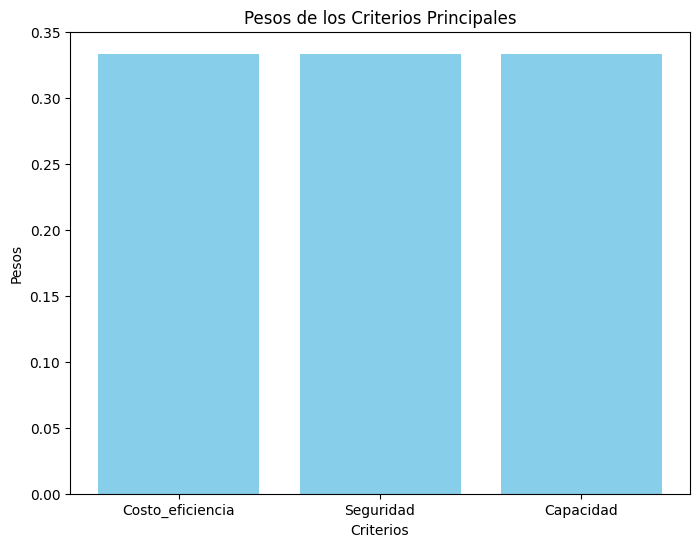

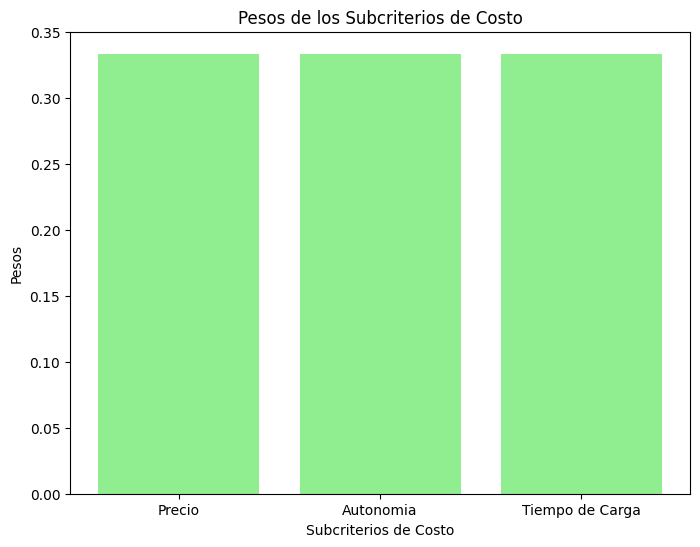

In [26]:
import matplotlib.pyplot as plt

# Gráfico de barras para los pesos de los criterios principales
plt.figure(figsize=(8, 6))
plt.bar(['Costo_eficiencia', 'Seguridad', 'Capacidad'], pesos_criterios, color='skyblue')
plt.xlabel('Criterios')
plt.ylabel('Pesos')
plt.title('Pesos de los Criterios Principales')
plt.show()

# Gráfico de barras para los pesos de los subcriterios de Costo_eficiencia
plt.figure(figsize=(8, 6))
plt.bar(['Precio', 'Autonomia','Tiempo de Carga'], pesos_Costo, color='lightgreen')
plt.xlabel('Subcriterios de Costo')
plt.ylabel('Pesos')
plt.title('Pesos de los Subcriterios de Costo')
plt.show()


**Puntaje de las Alternativas**

/tmp/ipykernel_929/3432495953.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=alternativas, y = puntajes_totales, palette='muted')


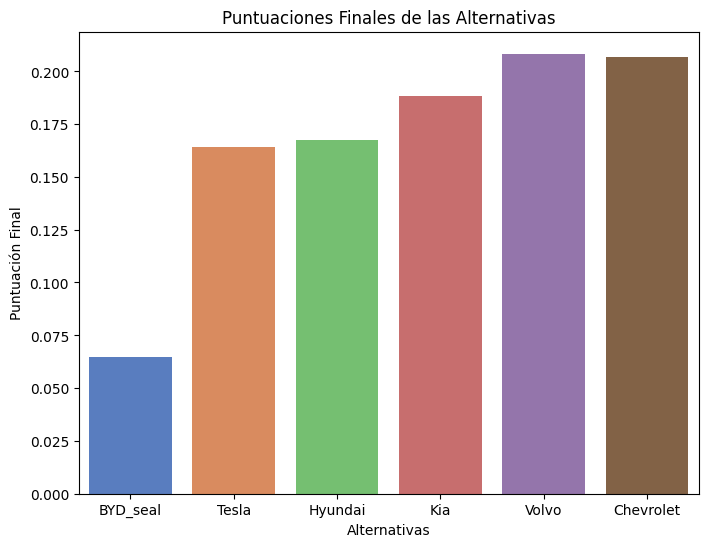

In [27]:

plt.figure(figsize=(8, 6))
sns.barplot(x=alternativas, y = puntajes_totales, palette='muted')
plt.title('Puntuaciones Finales de las Alternativas')
plt.xlabel('Alternativas')
plt.ylabel('Puntuación Final')
plt.show()


/tmp/ipykernel_929/1986737812.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  weights = np.concatenate((weights, [weights[0]]))


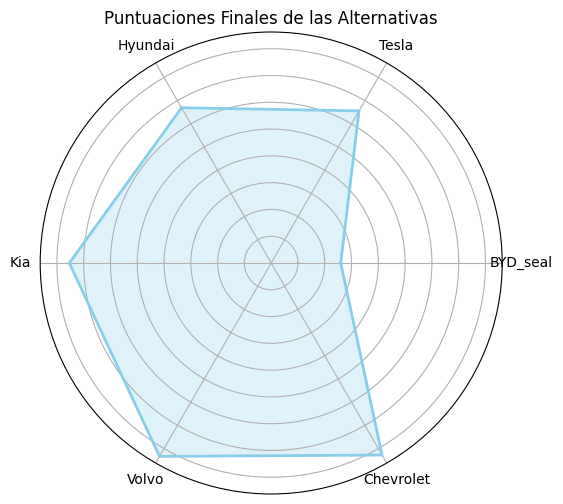

In [28]:
# Graficar los puntajes de las alternativas
def plot_alternatives(weights, labels, title):
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    weights = np.concatenate((weights, [weights[0]]))
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.fill(angles, weights, color='skyblue', alpha=0.25)
    ax.plot(angles, weights, color='skyblue', linewidth=2)
    ax.set_yticklabels([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    plt.title(title)
    plt.show()

plot_alternatives(puntajes_totales, alternativas, "Puntuaciones Finales de las Alternativas")


# Adicion - Consistencia de los juicios y análisis de sensibilidad

*Continuación del Taller 1. Se profundiza en la medición de la consistencia de las matrices de comparación pareada y en la robustez de la decisión mediante simulación de Montecarlo.*


## Índice y razón de consistencia (CR)

### Idea central

La **consistencia** de los juicios se relaciona con la **transitividad** de las preferencias. Por ejemplo, si el criterio $A$ es el doble de importante que $B$, y $B$ el doble que $C$, la consistencia cardinal perfecta exige que $A$ se juzgue **4 veces** más importante que $C$. Como los juicios humanos rara vez son perfectos, Saaty definió la **Razón de Consistencia (CR)**, que mide cuánto se alejan los juicios de la consistencia perfecta:

$$\text{CR} = \frac{\text{IC}}{\text{IA}} \qquad \text{Si } \text{CR} \le 0.10 \Rightarrow \text{consistencia aceptable}$$

donde **IC** es el *índice de consistencia* (depende del autovalor máximo $\lambda_{max}$ y del tamaño $N$ de la matriz) e **IA** es el *índice aleatorio* (valor de referencia de una matriz llenada al azar).

### Cálculo de $\lambda_{max}$ (método manual de Saaty)

Para cada matriz de comparaciones $[A]$ con vector de pesos $[B]$:

1. Multiplicar $[A]\,[B] = [C]$ (nuevo vector).
2. Dividir cada elemento de $[C]$ por su correspondiente en $[B]$, obteniendo $[D]$.
3. $\lambda_{max} = $ promedio de los elementos de $[D]$.

### Fórmulas

$$\text{IC} = \frac{\lambda_{max} - N}{N - 1} \qquad\qquad \text{CR} = \frac{\text{IC}}{\text{IA}}$$

**Índice aleatorio IA** (aproximado por Saaty con muchos ensayos) (RI - Random Index):

| N  | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|----|---|---|-----|-----|-----|-----|-----|-----|-----|-----|
| IA | 0 | 0 | 0.58| 0.90| 1.12| 1.24| 1.32| 1.41| 1.45| 1.49|

### ¿Por qué funciona?

Si los juicios fueran perfectamente consistentes, existirían pesos $w_i$ tales que $a_{ij} = w_i / w_j$. En ese caso se cumple $A\,w = \lambda_{max}\,w$ con $\lambda_{max} = N$, y $(Aw)_i / w_i$ es constante. **Cuanto más se aleja $\lambda_{max}$ de $N$, más inconsistente es el juicio.** Por eso IC crece con $(\lambda_{max}-N)$.


In [29]:
# Complemento del Taller 2: funciones para analizar la consistencia de cualquier matriz.
# Se agregan con nombres nuevos para NO alterar indice_inconsistencia ni razon_consistencia.

# Indice aleatorio (IA) de Saaty segun el tamano N de la matriz
IA_SAATY = {1: 0.00, 2: 0.00, 3: 0.58, 4: 0.90, 5: 1.12,
            6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}

def lambda_max_manual(matriz, pesos):
    """Autovalor maximo por el metodo manual de Saaty:
       [C] = [A][B];  [D] = [C]/[B];  lambda_max = promedio de [D]."""
    matriz = np.array(matriz, dtype=float)
    pesos = np.array(pesos, dtype=float)
    C = matriz @ pesos          # paso 1: A * w
    D = C / pesos               # paso 2: division elemento a elemento
    return D.mean()             # paso 3: promedio

def analizar_consistencia(matriz, nombre=""):
    """Calcula pesos, lambda_max (manual), IC, IA y CR de una matriz de comparaciones.
       Devuelve un diccionario con el resumen e imprime el veredicto."""
    matriz = np.array(matriz, dtype=float)
    N = matriz.shape[0]
    # Se reutiliza calcular_pesos (vector propio) definido en el Taller 1
    pesos, _ = calcular_pesos(matriz)
    lmax = lambda_max_manual(matriz, pesos)
    IC = (lmax - N) / (N - 1) if N > 1 else 0.0
    IA = IA_SAATY.get(N, np.nan)
    CR = IC / IA if IA and IA > 0 else 0.0   # para N<=2, IA=0 => CR no aplica
    if N <= 2:
        veredicto = "N<=2: la comparacion es siempre consistente (no se calcula CR)."
    else:
        veredicto = "Consistencia ACEPTABLE (CR<=0.10)" if CR <= 0.10 else "INCONSISTENTE (CR>0.10): revisar juicios"
    print(f"[{nombre}]  N={N}  lambda_max={lmax:.4f}  IC={IC:.4f}  IA={IA}  CR={CR:.4f}  -> {veredicto}")
    return {"nombre": nombre, "N": N, "lambda_max": lmax, "IC": IC, "IA": IA, "CR": CR}


### Ejemplo (matriz $5\times5$)

Se reproduce el ejemplo del material de clase, cuya matriz de orden 5 arroja $\lambda_{max}\approx 5.31$, $\text{IC}\approx 0.08$ y $\text{CR}\approx 0.07 < 0.10$, por lo que **se acepta el nivel de inconsistencia**.


In [30]:
# Matriz 5x5 del ejemplo de clase
matriz_ejemplo = np.array([
    [1,    1/3, 5,   6,   5  ],
    [3,    1,   6,   7,   6  ],
    [1/5,  1/6, 1,   3,   1  ],
    [1/6,  1/7, 1/3, 1,   1/4],
    [1/5,  1/6, 1,   4,   1  ],
])

res_ejemplo = analizar_consistencia(matriz_ejemplo, "Ejemplo clase 5x5")

# Verificacion cruzada con el autovalor de numpy (numpy.linalg.eig) (metodo del vector propio)
_, lmax_numpy = calcular_pesos(matriz_ejemplo)
print(f"\nVerificacion: lambda_max por numpy.linalg.eig = {lmax_numpy:.4f}")
print("Ambos metodos (manual y vector propio) deben coincidir aproximadamente.")


[Ejemplo clase 5x5]  N=5  lambda_max=5.3029  IC=0.0757  IA=1.12  CR=0.0676  -> Consistencia ACEPTABLE (CR<=0.10)

Verificacion: lambda_max por numpy.linalg.eig = 5.3029
Ambos metodos (manual y vector propio) deben coincidir aproximadamente.


### Aplicación a las matrices del Taller 1

Se evalúa la consistencia de todas las matrices de comparación pareada usadas en el caso del proveedor. Se reutilizan directamente las matrices ya definidas .


In [31]:
# Se analizan todas las matrices pareadas del Taller 1 con tamaño igual o mayor a 3
matrices_taller1 = {
    "Criterios (Costo/Seguridad/Capacidad)": matriz_Criterios,
    "Subcriterio Costo":    matriz_Costo,
   }

resultados_consistencia = [analizar_consistencia(m, nombre) for nombre, m in matrices_taller1.items()]

# Tabla resumen
tabla_CR = pd.DataFrame(resultados_consistencia)[["nombre", "N", "lambda_max", "IC", "IA", "CR"]]
print("\nResumen de consistencia:")
print(tabla_CR.round(4).to_string(index=False))


[Criterios (Costo/Seguridad/Capacidad)]  N=3  lambda_max=3.0000  IC=0.0000  IA=0.58  CR=0.0000  -> Consistencia ACEPTABLE (CR<=0.10)
[Subcriterio Costo]  N=3  lambda_max=3.0000  IC=0.0000  IA=0.58  CR=0.0000  -> Consistencia ACEPTABLE (CR<=0.10)

Resumen de consistencia:
                               nombre  N  lambda_max  IC   IA  CR
Criterios (Costo/Seguridad/Capacidad)  3         3.0 0.0 0.58 0.0
                    Subcriterio Costo  3         3.0 0.0 0.58 0.0


### Demostración de consistencia perfecta

Si conocemos de antemano los pesos $w = [0.5,\ 0.3,\ 0.2]$ y construimos la matriz "ideal" con $a_{ij} = w_i/w_j$, el resultado debe ser $\lambda_{max}=N=3$, $\text{IC}=0$ y $\text{CR}=0$: **consistencia perfecta**.


In [32]:
# Se construye una matriz perfectamente consistente a partir de pesos conocidos
w_ideal = np.array([0.5, 0.3, 0.2])
matriz_ideal = np.array([[w_ideal[i] / w_ideal[j] for j in range(3)] for i in range(3)])

print("Matriz ideal (a_ij = w_i / w_j):")
print(np.round(matriz_ideal, 3))
print()

# Analizar la consistencia y capturar el resultado
res_ideal = analizar_consistencia(matriz_ideal, "Matriz perfectamente consistente")

print("\nDetalles de consistencia de la matriz ideal:")
print(f"  N: {res_ideal['N']}")
print(f"  Lambda Max: {res_ideal['lambda_max']:.4f}")
print(f"  IC (Índice de Consistencia): {res_ideal['IC']:.4f}")
print(f"  IA (Índice Aleatorio): {res_ideal['IA']}")
print(f"  CR (Razón de Consistencia): {res_ideal['CR']:.4f}")

if res_ideal['CR'] == 0:
    print("\nConclusión: La matriz es perfectamente consistente (CR=0) ya que fue construida a partir de pesos ideales.")
else:
    print(f"\nConclusión: La matriz tiene un CR de {res_ideal['CR']:.4f}.")


Matriz ideal (a_ij = w_i / w_j):
[[1.    1.667 2.5  ]
 [0.6   1.    1.5  ]
 [0.4   0.667 1.   ]]

[Matriz perfectamente consistente]  N=3  lambda_max=3.0000  IC=0.0000  IA=0.58  CR=0.0000  -> Consistencia ACEPTABLE (CR<=0.10)

Detalles de consistencia de la matriz ideal:
  N: 3
  Lambda Max: 3.0000
  IC (Índice de Consistencia): 0.0000
  IA (Índice Aleatorio): 0.58
  CR (Razón de Consistencia): 0.0000

Conclusión: La matriz es perfectamente consistente (CR=0) ya que fue construida a partir de pesos ideales.


#**Análisis de sensibilidad manual**

In [33]:
import ipywidgets as widgets
from ipywidgets import interact

def calcular_puntuaciones_interactivo(peso_precio, peso_autonomia, peso_tiempo, peso_seguridad, peso_tipo, Peso_Maletero):
    # Normalizar los pesos para que sumen 1
    total = peso_precio + peso_autonomia + peso_tiempo+ peso_seguridad+ peso_tipo+ Peso_Maletero
    peso_precio/= total
    peso_autonomia/= total
    peso_tiempo/= total
    peso_seguridad/= total
    peso_tipo/= total
    Peso_Maletero/= total

    vector_pesos_globalesN= np.array([peso_precio,
                                  peso_autonomia,
                                  peso_tiempo,
                                  peso_seguridad,
                                  peso_tipo,
                                  Peso_Maletero
                                  ])

    matriz_ponderadaN = matriz_2normalizada.mul(vector_pesos_globalesN, axis=0)

    puntuaciones_finales = matriz_ponderadaN.sum(axis=0)

    print("Puntaje total por carro:")
    print(puntuaciones_finales.round(4))
    # Determinar la mejor alternativa con los nuevos pesos
    mejor_alternativa = alternativas[np.argmax(puntuaciones_finales)]

    # Visualizar las puntuaciones
    plt.figure(figsize=(8, 6))
    plt.bar(alternativas, puntuaciones_finales, color='skyblue')
    plt.title('Puntuaciones Finales de las Alternativas')
    plt.ylabel('Puntuación')
    plt.show()

    print(f"Con los pesos ajustados: Precio={peso_precio:.2f}, Autonomia={peso_autonomia:.2f},Tiempo={peso_tiempo:.2f},Seguridad={peso_seguridad:.2f}, Tipo={peso_tipo:.2f},Maletero={Peso_Maletero:.2f}")
    print("La mejor alternativa es:", mejor_alternativa)

# Crear sliders para los pesos
peso_precio_slider = widgets.FloatSlider(value=0.166, min=0, max=1, step=0.01, description='Peso Precio:')
peso_autonomia_slider = widgets.FloatSlider(value=0.166, min=0, max=1, step=0.01, description='Peso autonomia:')
peso_tiempo_slider = widgets.FloatSlider(value=0.166, min=0, max=1, step=0.01, description='Peso tiempo de carga:')
peso_seguridad_slider = widgets.FloatSlider(value=0.166, min=0, max=1, step=0.01, description='Peso Seguridad:')
peso_tipo_slider = widgets.FloatSlider(value=0.166, min=0, max=1, step=0.01, description='Peso Tipo de carro:')
peso_maletero_slider = widgets.FloatSlider(value=0.166, min=0, max=1, step=0.01, description='Peso maletero:')


# Crear la interfaz interactiva
interact(calcular_puntuaciones_interactivo,
         peso_precio=peso_precio_slider,
         peso_autonomia=peso_autonomia_slider,
         peso_tiempo=peso_tiempo_slider,
         peso_seguridad=peso_seguridad_slider,
         peso_tipo=peso_tipo_slider,
         Peso_Maletero=peso_maletero_slider);

interactive(children=(FloatSlider(value=0.166, description='Peso Precio:', max=1.0, step=0.01), FloatSlider(va…

## Análisis de sensibilidad por simulación de Montecarlo

Los pesos de importancia son **subjetivos** (dependen del ánimo del decisor, de su comprensión del problema, etc.). El análisis de sensibilidad verifica la **robustez** de la decisión ante cambios en esos pesos:

- Una alternativa es **más robusta** si, al cambiar los pesos, permanece en una buena jerarquía (1.º o 2.º).
- El problema es **sensible a un criterio** si, cambiando solo el peso de ese criterio, cambia fuertemente el orden de la jerarquía.

En lugar de mover los pesos a mano, la **simulación de Montecarlo** genera muchos juegos de pesos aleatorios, recalcula el puntaje AHP en cada iteración y estima la **probabilidad de que cada alternativa quede en el primer lugar**. Aquí se aplican perturbaciones aleatorias sobre los pesos globales del caso del proveedor (`vector_pesos_globales`) reutilizando la matriz doblemente normalizada (`matriz_2normalizada`).


In [45]:
# Simulacion de Montecarlo para el analisis de sensibilidad de los pesos
np.random.seed(42)  # reproducibilidad

N_ITER = 500
# Matriz doblemente normalizada (criterios de ultimo nivel x carros)
M = matriz_2normalizada.values           # forma: (6 criterios, 3 carros)
alternativas_mc = list(matriz_2normalizada.columns)
n_alt = M.shape[1]

# Concentracion de la distribucion Dirichlet centrada en los pesos originales:
# valores altos = pesos cercanos a los originales; se usa para perturbar suavemente.
concentracion = 50.0
alpha = np.clip(vector_pesos_globales, 1e-6, None) * concentracion

conteo_ganador = np.zeros(n_alt)   # veces que cada alternativa queda de primera
suma_rangos = np.zeros(n_alt)      # para el rango promedio

for _ in range(N_ITER):
    #pesos_sim = np.random.dirichlet(alpha)      # nuevos pesos
    pesos_sim = np.random.uniform(low=0.0, high=1.0, size=6)

    puntajes_sim = pesos_sim @ M                # puntaje AHP de cada carro
    ganador = np.argmax(puntajes_sim)
    conteo_ganador[ganador] += 1
    # rango: 1 = mejor
    rangos = (-puntajes_sim).argsort().argsort() + 1
    suma_rangos += rangos

prob_ganar = conteo_ganador / N_ITER
rango_promedio = suma_rangos / N_ITER

sensibilidad = pd.DataFrame({
    "Probabilidad de ser #1": prob_ganar.round(3),
    "Rango promedio": rango_promedio.round(2),
}, index=alternativas_mc).sort_values("Probabilidad de ser #1", ascending=False)

print(f"Analisis de sensibilidad Montecarlo ({N_ITER} iteraciones):")
print(sensibilidad)

alt_robusta = sensibilidad.index[0]
print(f"\nLa alternativa mas robusta al cambio de pesos es: {alt_robusta} "
      f"(probabilidad {sensibilidad.iloc[0,0]:.1%} de quedar de primera).")


Analisis de sensibilidad Montecarlo (500 iteraciones):
           Probabilidad de ser #1  Rango promedio
Chevrolet                   0.520            2.01
Volvo                       0.184            2.95
Tesla                       0.154            3.26
Kia                         0.142            2.69
BYD_seal                    0.000            5.83
Hyundai                     0.000            4.25

La alternativa mas robusta al cambio de pesos es: Chevrolet (probabilidad 52.0% de quedar de primera).


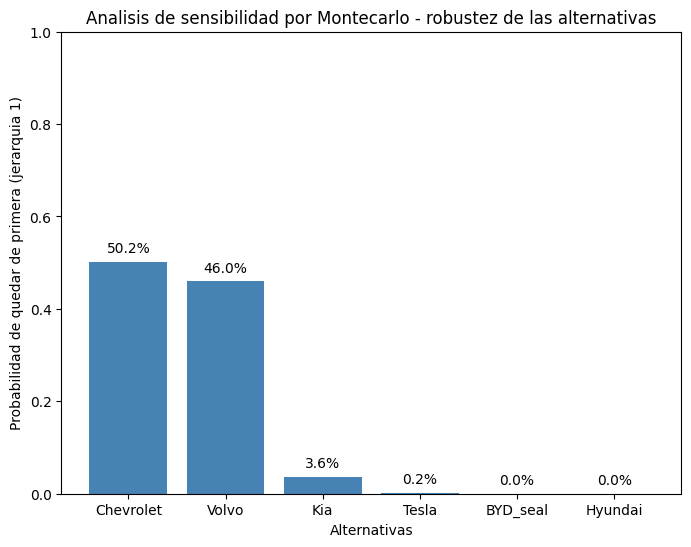

In [35]:
# Grafico de la probabilidad de que cada alternativa quede en el primer lugar
plt.figure(figsize=(8, 6))
plt.bar(sensibilidad.index, sensibilidad["Probabilidad de ser #1"], color="steelblue")
plt.ylabel("Probabilidad de quedar de primera (jerarquia 1)")
plt.xlabel("Alternativas")
plt.title("Analisis de sensibilidad por Montecarlo - robustez de las alternativas")
plt.ylim(0, 1)
for i, v in enumerate(sensibilidad["Probabilidad de ser #1"]):
    plt.text(i, v + 0.02, f"{v:.1%}", ha="center")
plt.show()


%RELLENAR%
# Preguntas de análisis - Taller 1


1.	Introduzca deliberadamente un juicio inconsistente en la primera matriz de comparaciones pareadas y observe cómo aumentan λmax y CR. ¿Qué concluye?.

2.	Los pesos se obtienen de normalizar por columnas y promediar por filas de la matriz de comparaciones. Según si propia deducción, porqué,  de una matriz de comparaciones pareadas, se puede deducir la importancia relativa de cada criterio de esa forma (no use Chat de IA)?

____________________________________________________________________________

3.	La matriz de consecuencias se normaliza dos veces (min-max y luego por suma de filas). ¿Qué logra cada normalización y por qué es necesario multiplicar por -1 los criterios a minimizar antes de normalizar?

4.	AHP usa una regla de decisión compensatoria: una gran desventaja en un criterio puede compensarse con una gran ventaja en otro. ¿En qué situaciones esto podría llevar a una mala decisión? ¿Qué método alternativo mitigaría este efecto?

5.	¿Por qué el umbral de aceptación de Saaty es CR≤0.10 y no, por ejemplo, 0? ¿Qué significaría exigir consistencia perfecta a un decisor humano?

6.	En el análisis de sensibilidad, ¿qué diferencia hay entre una alternativa que gana con alta probabilidad y una que tiene buen rango promedio pero baja probabilidad de ser la primera? ¿Cuál preferiría y por qué?

7.	Compare la sensibilidad manual (cambiar un peso a la vez) con la simulación de Montecarlo (cambiar todos los pesos simultáneamente). ¿Qué información aporta cada enfoque sobre la robustez de la decisión?



# Consideración adicional


> **Nota:** las dos ideas siguientes **no forman parte del AHP clásico**. Se incluyen como consideración adicional para tenerlas presentes.


### 1. Criterio cualitativo con escala

**¿Dónde iría?** En los pasos 4–6 (valoración y normalización de la matriz de consecuencias), cuando un criterio **no es numérico**. En el caso del tipo de carro como *Sedan, Crossover,etc*. Antes de poder normalizar, se traduce cada categoría a un número mediante una **escala ordinal fija** (por ejemplo 0, 0.25, 0.50, 0.75, 1.00). A partir de ahí el criterio entra al mismo flujo de normalización que los demás.

**Implicación.** Es una ventaja de AHP: permite mezclar criterios cuantitativos y cualitativos. Pero la escala elegida es una **decisión subjetiva del decisor**, no un dato objetivo: cambiar los valores de la escala puede alterar la jerarquía. Debe justificarse.

### 2. Exponente de la función de valor (control de compensación)

**¿Dónde iría?** Entre la segunda normalización (paso 7) y la ponderación (paso 8). Cada valor normalizado se eleva a un **exponente $E$** antes de multiplicarlo por el peso global:

$$C_{AHP}(A_j) = \sum_{i} w_i \, \left(Z'_{ij}\right)^{E}$$

- $E = 1$ >> **AHP clásico**, totalmente **compensatorio**: un valor muy bajo en un criterio puede compensarse con uno muy alto en otro.
- $E < 1$ >> función de valor **cóncava**: penaliza más los valores bajos, **atenuando la compensación**.

**Implicación.** El exponente es una "perilla" que acerca el AHP hacia métodos **menos compensatorios** (como la Programación de Compromiso, ojo en esta el exponente debe ser mayor de 1 porque es para minimizar distancia al ideal), abordando justamente la desventaja del AHP: que grandes deficiencias se compensen con grandes virtudes.


In [36]:

# --- Idea adicional: exponente de la funcion de valor sobre el caso del carro ---
def puntajes_con_exponente(matriz_norm, pesos, exponente):
    """Calificacion AHP aplicando un exponente a los valores normalizados
       antes de ponderar por los pesos globales."""
    M = matriz_norm.values                      # criterios x alternativas
    puntajes = pesos @ (M ** exponente)
    return pd.Series(puntajes, index=matriz_norm.columns)

print("\n2) Efecto del exponente de la funcion de valor (caso carro):")
for E in [1.0, 0.1]:
    p = puntajes_con_exponente(matriz_2normalizada, vector_pesos_globales, E)
    jer = p.rank(ascending=False).astype(int)
    etiqueta = "AHP clasico (compensatorio)" if E == 1.0 else "atenua la compensacion"
    print(f"\n   Exponente E={E} -> {etiqueta}")
    print(pd.DataFrame({"Puntaje": p.round(4), "Jerarquia": jer}).sort_values("Jerarquia").to_string())



2) Efecto del exponente de la funcion de valor (caso carro):

   Exponente E=1.0 -> AHP clasico (compensatorio)
           Puntaje  Jerarquia
Volvo       0.2084          1
Chevrolet   0.2070          2
Kia         0.1884          3
Hyundai     0.1673          4
Tesla       0.1640          5
BYD_seal    0.0649          6

   Exponente E=0.1 -> atenua la compensacion
           Puntaje  Jerarquia
Kia         0.8383          1
Chevrolet   0.8332          2
Hyundai     0.7487          3
Tesla       0.7030          4
Volvo       0.6360          5
BYD_seal    0.3202          6


In [37]:
#PARA MAYOR INFORMACION, SI SE TIENE UN CRITERIOS CUALITATIVO CON ESCALA POR EJEMPLO TIPO DE VEHICULO
# Escala ordinal -> numerica (misma logica de la clase para criterios cualitativos)
escala_cualitativa = {"Hatchback": 0.6, "Sedan": 0.7, "Crossover": 0.8,
                      "SUVCompacta": 0.9, "SUVmediana": 1.00}

# Ejemplo: una columna cualitativa hipotetica para 3 alternativas
valores_cualitativos = ["Hatchback", "Crossover", "SUVmediana"]
valores_numericos = [escala_cualitativa[v] for v in valores_cualitativos]
print("1) Criterio cualitativo mapeado a numerico:")
print("   ", dict(zip(valores_cualitativos, valores_numericos)))
print("   (estos numeros luego entran a la normalizacion como cualquier otro criterio)")


1) Criterio cualitativo mapeado a numerico:
    {'Hatchback': 0.6, 'Crossover': 0.8, 'SUVmediana': 1.0}
   (estos numeros luego entran a la normalizacion como cualquier otro criterio)
